# 05 · Seleção de algoritmos

Com as features definidas, agora comparamos **famílias de algoritmos** sob as mesmas condições:
mesmas features, mesmos 3 folds temporais e hiperparâmetros pré-definidos **sem tuning**. 

O objetivo principal é saber qual família de algoritmos tem maior potencial.

- **Regressão logística** → baseline linear, interpretável e muito rápida, mas requer tratamento de nulos/escala;
- **Random Forest** → árvores em *bagging*: robusta, captura não linearidades;
- **XGBoost** → *gradient boosting*, estado da arte em dados tabulares;
- **LightGBM** → *gradient boosting* com histogramas: rápido para treinar e para inferir;
- **CatBoost** → *gradient boosting* com *ordered boosting*, menos propenso a overfitting.

**Critérios de escolha,** em ordem:
1. **PR AUC médio** e sua estabilidade entre folds;
2. **ROC AUC / Recall @ FPR 5%**; 
3. Latência de inferência, tempo de treino e simplicidade de implantação (**custo operacional**).

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from fraude import validacao

In [2]:
%%time
base = dados.carregar_base()
dev = base[base["particao"] != "teste"].reset_index(drop=True)
folds = validacao.construir_folds(dev)   # mesmas features do nb 04 (configuração D)
print(len(folds), "folds |", folds[0].X_tr.shape[1], "features")

3 folds | 25 features
CPU times: total: 19.7 s
Wall time: 38.7 s


## 1. Candidatos *(pergunta 1)*

A regressão logística precisa de um pré-processamento próprio: 
- Transformação **log com sinal** para reduzir a assimetria entre variáveis numéricas;
- **Imputação pela mediana** + **com indicador de ausência** para variáveis nulas (o nulo carrega informação);
- Padronização (**StandardScaler**). 

Já os modelos de árvore recebem as features como estão e tratam
nulos nativamente.

In [3]:
log_sinal = FunctionTransformer(lambda X: np.sign(X) * np.log1p(np.abs(X)))

candidatos = {
    "Regressão logística": make_pipeline(
        log_sinal, SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
        LogisticRegression(C=1.0, max_iter=3000)),
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=20, max_features="sqrt",
                                            n_jobs=-1, random_state=cfg.SEED),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=6, subsample=0.8,
                             colsample_bytree=0.8, min_child_weight=5, tree_method="hist",
                             n_jobs=-1, random_state=cfg.SEED),
    "LightGBM": lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                   random_state=cfg.SEED, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=800, learning_rate=0.05, depth=6, random_seed=cfg.SEED,
                                   verbose=0, thread_count=-1, allow_writing_files=False),
}

In [4]:
%%time
resultados, oofs = [], {}
for nome, modelo in candidatos.items():
    r, oof = validacao.avaliar_cv(modelo, folds, nome=nome)
    resultados.append(r)
    oofs[nome] = oof
resultados = pd.concat(resultados, ignore_index=True)
comparacao = validacao.resumo_cv(resultados)
comparacao

CPU times: total: 6min 1s
Wall time: 52.8 s


,PR AUC (média),ROC AUC (média),Recall @ FPR 5% (média),treino (s) (média),predição (µs/transação) (média),PR AUC (dp),ROC AUC (dp)
modelo,,,,,,,
XGBoost,0.4182,0.8533,0.4844,1.0679,1.6119,0.0102,0.0007
LightGBM,0.4177,0.8534,0.4807,0.8072,6.7389,0.0093,0.0016
CatBoost,0.4163,0.8543,0.4802,6.0962,0.2907,0.0094,0.0018
Random Forest,0.3967,0.8447,0.4713,8.9908,7.7874,0.0051,0.0012
Regressão logística,0.3764,0.8486,0.4612,0.2313,0.9969,0.0028,0.0020


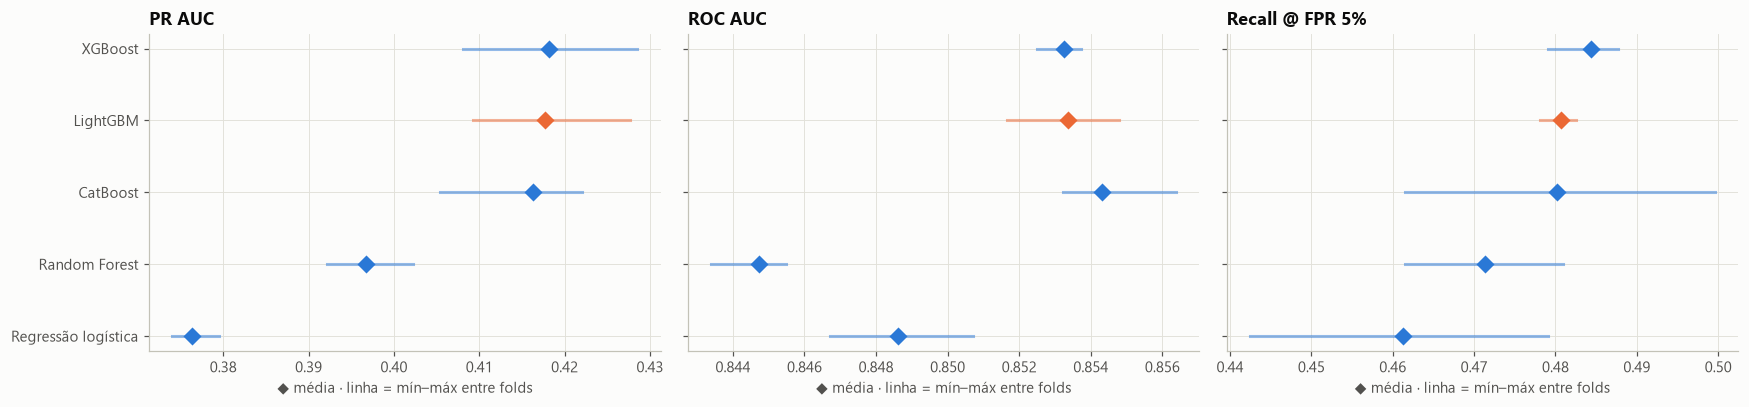

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
ordem = comparacao.index.tolist()
for ax, met in zip(axes, ["PR AUC", "ROC AUC", "Recall @ FPR 5%"]):
    for i, nome in enumerate(ordem):
        v = resultados.loc[resultados["modelo"] == nome, met]
        cor = gr.LARANJA if nome == "LightGBM" else gr.AZUL
        ax.plot([v.min(), v.max()], [i, i], color=cor, lw=2, alpha=0.5)
        ax.scatter(v.mean(), i, color=cor, s=70, marker="D", zorder=3)
    ax.set_yticks(range(len(ordem)), ordem if ax is axes[0] else [""] * len(ordem))
    ax.invert_yaxis()
    ax.set(title=met, xlabel="◆ média · linha = mín–máx entre folds")
plt.tight_layout()

**Leitura:**
- Os três ***gradient boostings*** (LightGBM, XGBoost, CatBoost) ficam **praticamente empatados**, com
  diferenças menores que a variação entre folds. 
    - Isso mostra que o limite está na informação das features, e não no algoritmo.
- **Random Forest** fica um degrau abaixo em PR AUC (~0,40) e é a pior em ROC AUC.
- A **regressão logística** tem ROC AUC razoável (~0,849), mas o **pior PR AUC (~0,38)**. 
  - Ela ordena
  bem a massa de transações, mas erra no topo do ranking, onde estão as fraudes mais
  "óbvias" e onde se decide o bloqueio. 
  
> As relações são fortemente não lineares, o que um modelo linear não capturaria normalmente.

## 3. Custo operacional (relevante para a resposta online, pergunta 7)

In [6]:
custo = comparacao[["treino (s) (média)", "predição (µs/transação) (média)"]].copy()
custo.columns = ["tempo de treino (s)", "predição em lote (µs/transação)"]
custo.sort_values("predição em lote (µs/transação)")

,tempo de treino (s),predição em lote (µs/transação)
modelo,,
CatBoost,6.0962,0.2907
Regressão logística,0.2313,0.9969
XGBoost,1.0679,1.6119
LightGBM,0.8072,6.7389
Random Forest,8.9908,7.7874


- **Treino:** o LightGBM é o boosting mais rápido (< 1 s por fold). CatBoost e Random Forest são
  ~7–12x mais lentos. Isso pesa num ciclo de retreino frequente e de tuning.
- **Predição em lote:** todos ficam em poucos **microssegundos por transação**. O CatBoost (árvores
  simétricas) é o mais rápido em lote. Em qualquer caso, a diferença é irrelevante perto do restante da
  cadeia online (rede, busca de features).
- A latência que importa online é a **por requisição única** (sem o benefício do lote), medida no
  notebook 09.

## 4. Conclusão *(pergunta 1)*

**Síntese da performance de cada modelo**
| Critério | LightGBM | XGBoost | CatBoost | Random Forest | Logística |
|---|---|---|---|---|---|
| PR AUC / ROC AUC | ✅ topo (empate técnico) | ✅ topo | ✅ topo | ⚠️ abaixo | ❌ bem abaixo |
| Estabilidade entre folds | ✅ | ✅ | ✅ | ✅ | ✅ |
| Treino / inferência | ✅ treino mais rápido; µs | ✅ µs | ⚠️ treino ~7x mais lento | ❌ pesado | ✅ mínimo |
| Nulos nativos | ✅ | ✅ | ✅ | ✅ | ❌ |
| Explicabilidade (SHAP) | ✅ TreeSHAP | ✅ | ✅ | ✅ | ✅ coeficientes |

>**Escolha**: LightGBM 

- Está no grupo de melhor desempenho, em empate técnico com XGBoost e CatBoost
(diferenças de PR AUC < 0,002); 
- O desempate é **operacional**:
treino mais rápido (tuning e retreinos frequentes), artefato pequeno, nulos nativos e suporte a
SHAP e a otimização de inferência (ONNX/Treelite); 
- A regressão logística fica registrada como **plano B** para um
cenário de latência extrema ou exigência regulatória de modelo linear